In [2]:
!pip install imagehash

In [3]:
import pandas as pd
import matplotlib.image as mpimg
import cv2, os
import shutil
import imutils
import numpy as np
import imagehash
import zipfile
import matplotlib.pyplot as plt
import time
from collections import Counter
from PIL import Image
from collections import defaultdict
import tensorflow as tf
import seaborn as sns
from os import listdir
plt.style.use('ggplot')
%matplotlib inline
print("All required libraries imported successfully.")

All required libraries imported successfully.


In [4]:
# Mount Google Drive

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# Extract the ZIP
DATASET_PATH = "/content/drive/MyDrive/Brain_Tumor_CNN_Project/dataset/Epic and CSCR hospital Dataset"

if os.path.isdir(DATASET_PATH):
    print("Dataset folder loaded successfully!")
    print("Files and subfolders:")
    print(os.listdir(DATASET_PATH)[:20])
else:
    print("Folder not found. Please verify the path.")

Dataset folder loaded successfully!
Files and subfolders:
['Test', 'Train']


In [6]:
# Check the extracted files

DATASET_DIR = "/content/drive/MyDrive/Brain_Tumor_CNN_Project/dataset"
print(os.listdir(DATASET_DIR))

['Epic and CSCR hospital Dataset']


In [7]:
# define the path

PROJECT_DIR = "/content/drive/MyDrive/Brain_Tumor_CNN_Project"

DATASET_DIR = os.path.join(
    PROJECT_DIR,
    "dataset",
    "Epic and CSCR hospital Dataset"
)

TRAIN_DIR = os.path.join(DATASET_DIR, "Train")
TEST_DIR = os.path.join(DATASET_DIR, "Test")

print("Dataset path:", DATASET_DIR)
print("Train path:", TRAIN_DIR)
print("Test path:", TEST_DIR)

Dataset path: /content/drive/MyDrive/Brain_Tumor_CNN_Project/dataset/Epic and CSCR hospital Dataset
Train path: /content/drive/MyDrive/Brain_Tumor_CNN_Project/dataset/Epic and CSCR hospital Dataset/Train
Test path: /content/drive/MyDrive/Brain_Tumor_CNN_Project/dataset/Epic and CSCR hospital Dataset/Test


In [8]:
# count images in each class

VALID_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp")

def count_images(directory):

    counts = {}

    for class_name in sorted(os.listdir(directory)):

        class_path = os.path.join(directory, class_name)

        if os.path.isdir(class_path):

            count = sum(
                1
                for file_name in os.listdir(class_path)
                if file_name.lower().endswith(VALID_EXTENSIONS)
            )

            counts[class_name] = count

    return counts


train_counts = count_images(TRAIN_DIR)
test_counts = count_images(TEST_DIR)

print("TRAINING SET")
print("=" * 40)

for class_name, count in train_counts.items():
    print(f"{class_name:15s}: {count}")

total_train = sum(train_counts.values())
print("Total training images :", total_train)

print("\nTEST SET")
print("=" * 40)

for class_name, count in test_counts.items():
    print(f"{class_name:15s}: {count}")

total_test = sum(test_counts.values())
print("Total testing images :", total_test)

total_images = total_train + total_test
print("=" * 40)
print("\nTotal images :", total_images)

TRAINING SET
glioma         : 3018
meningioma     : 2183
notumor        : 1945
pituitary      : 2504
Total training images : 9650

TEST SET
glioma         : 756
meningioma     : 546
notumor        : 487
pituitary      : 626
Total testing images : 2415

Total images : 12065


In [11]:
# Add Duplicate & Train/Test Leakage Check
def get_image_hashes(directory):
    """Computes perceptual hashes for all images to find duplicates."""
    hash_dict = {}
    duplicates = []

    for class_name in sorted(os.listdir(directory)):
        class_path = os.path.join(directory, class_name)
        if not os.path.isdir(class_path):
            continue

        for filename in os.listdir(class_path):
            if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
                img_path = os.path.join(class_path, filename)
                try:
                    with Image.open(img_path) as img:
                        # Use perceptual hash (more robust than exact file match)
                        phash = str(imagehash.phash(img))
                        if phash in hash_dict:
                            duplicates.append((filename, hash_dict[phash], class_name))
                        else:
                            hash_dict[phash] = filename
                except Exception as e:
                    print(f"Error reading {img_path}: {e}")

    return hash_dict, duplicates

print("Checking for duplicates in TRAINING set...")
train_hashes, train_duplicates = get_image_hashes(TRAIN_DIR)
print(f"Found {len(train_duplicates)} duplicate/near-duplicate images in Training set.")

print("\nChecking for TRAIN/TEST data leakage (overlapping images)...")
test_hashes, test_duplicates = get_image_hashes(TEST_DIR)

# Find intersections between train and test hashes
leakage_count = 0
for phash in train_hashes:
    if phash in test_hashes:
        leakage_count += 1

print(f"WARNING: Found {leakage_count} images that exist in BOTH Train and Test sets!")
print("Action Required: These must be removed from the Test set during Preprocessing to prevent data leakage.")

Checking for duplicates in TRAINING set...
Found 2326 duplicate/near-duplicate images in Training set.

Checking for TRAIN/TEST data leakage (overlapping images)...
Action Required: These must be removed from the Test set during Preprocessing to prevent data leakage.


In [12]:
# Create a summary DataFrame
df_summary = pd.DataFrame({
    'Train': train_counts,
    'Test': test_counts
})
df_summary['Total'] = df_summary['Train'] + df_summary['Test']
df_summary['Train_%'] = (df_summary['Train'] / df_summary['Train'].sum() * 100).round(2)
df_summary['Test_%'] = (df_summary['Test'] / df_summary['Test'].sum() * 100).round(2)

print("=== CLASS DISTRIBUTION SUMMARY ===")
display(df_summary)

print("\nOBSERVATION:")
print(f"- The dataset is imbalanced. '{min(train_counts, key=train_counts.get)}' is the minority class in training.")
print("- ACTION: We will apply targeted Data Augmentation (rotation, flipping, zoom) in the Preprocessing notebook to balance the minority classes.")

=== CLASS DISTRIBUTION SUMMARY ===


,Train,Test,Total,Train_%,Test_%
glioma,3018,756,3774,31.27,31.30
meningioma,2183,546,2729,22.62,22.61
notumor,1945,487,2432,20.16,20.17
pituitary,2504,626,3130,25.95,25.92



OBSERVATION:
- The dataset is imbalanced. 'notumor' is the minority class in training.
- ACTION: We will apply targeted Data Augmentation (rotation, flipping, zoom) in the Preprocessing notebook to balance the minority classes.


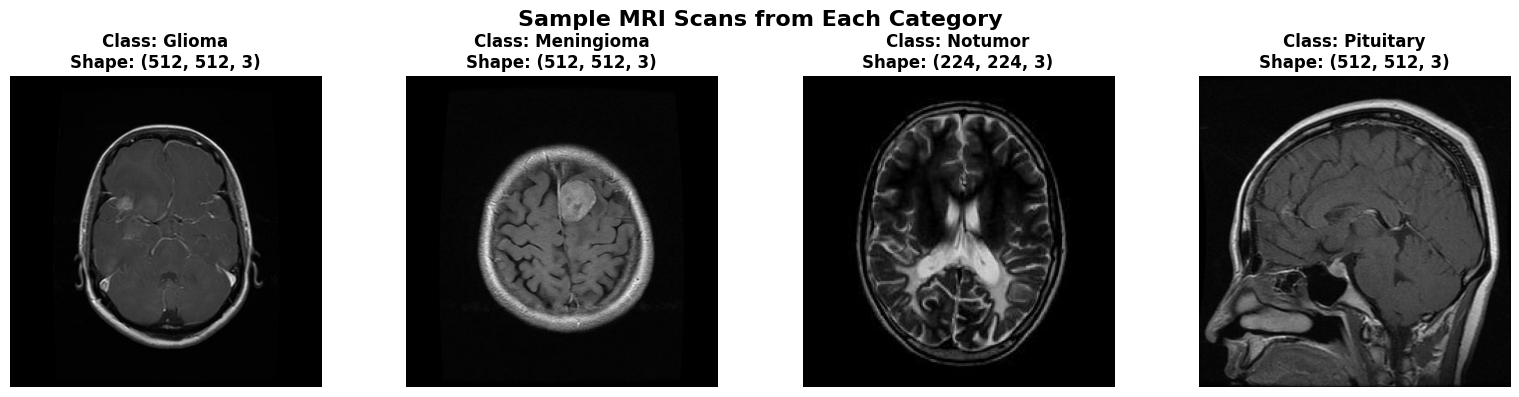

In [13]:
# Visualize 1 Sample from Each Class
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
classes = ['glioma','meningioma','notumor','pituitary']

for i, class_name in enumerate(classes):
    class_path = os.path.join(TRAIN_DIR, class_name)
    # Get the first image file in the folder
    img_files = [f for f in os.listdir(class_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    img_path = os.path.join(class_path, img_files[0])

    img = plt.imread(img_path)
    axes[i].imshow(img, cmap='gray') # Grayscale is standard for MRI
    axes[i].set_title(f"Class: {class_name.capitalize()}\nShape: {img.shape}", fontsize=12, fontweight='bold')
    axes[i].axis('off')

plt.suptitle('Sample MRI Scans from Each Category', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [14]:
# check the image dimensions

image_sizes = []

for class_name in classes:

    class_path = os.path.join(TRAIN_DIR, class_name)

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(VALID_EXTENSIONS)
    ]

    for image_file in image_files:

        image_path = os.path.join(class_path, image_file)

        try:
            image = Image.open(image_path)
            image_sizes.append(image.size)

        except Exception:
            pass

size_counts = Counter(image_sizes)

print("Number of different image sizes:", len(size_counts))
print("\nMost common image sizes:")

for size, count in size_counts.most_common(5):
    print(f"{size}: {count} images")

Number of different image sizes: 425

Most common image sizes:
(512, 512): 4858 images
(224, 224): 3123 images
(225, 225): 200 images
(236, 236): 101 images
(630, 630): 45 images


In [15]:
# check image channels/modes

image_modes = []

for class_name in classes:

    class_path = os.path.join(TRAIN_DIR, class_name)

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(VALID_EXTENSIONS)
    ]

    for image_file in image_files:

        image_path = os.path.join(class_path, image_file)

        try:
            image = Image.open(image_path)
            image_modes.append(image.mode)

        except Exception:
            pass

mode_counts = Counter(image_modes)

print("Image channel/mode distribution:")
print(mode_counts)

Image channel/mode distribution:
Counter({'RGB': 7287, 'L': 2357, 'RGBA': 5, 'P': 1})


In [16]:
# check pixel-value statistics

pixel_values = []

# Sample a limited number of images to keep EDA fast
max_images_per_class = 100

for class_name in classes:

    class_path = os.path.join(TRAIN_DIR, class_name)

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(VALID_EXTENSIONS)
    ]

    # Take up to 100 images from each class
    image_files = image_files[:max_images_per_class]

    for image_file in image_files:

        image_path = os.path.join(class_path, image_file)

        try:
            image = Image.open(image_path).convert("RGB")
            image_array = np.array(image)

            pixel_values.append(image_array)

        except Exception:
            pass

# Combine sampled images
pixel_values = np.concatenate(
    [img.reshape(-1, 3) for img in pixel_values],
    axis=0
)

print("Pixel statistics")
print("=" * 40)

print("Minimum pixel value :", pixel_values.min())
print("Maximum pixel value :", pixel_values.max())
print("Mean pixel value    :", np.round(pixel_values.mean(),2))
print("Standard deviation  :", np.round(pixel_values.std(),2))

Pixel statistics
Minimum pixel value : 0
Maximum pixel value : 255
Mean pixel value    : 41.41
Standard deviation  : 45.01


In [17]:
# image format analysis

format_counts = Counter()

for dataset_name, dataset_dir in [
    ("Train", TRAIN_DIR),
    ("Test", TEST_DIR)
]:

    for class_name in sorted(os.listdir(dataset_dir)):

        class_path = os.path.join(dataset_dir, class_name)

        if not os.path.isdir(class_path):
            continue

        for image_file in os.listdir(class_path):

            if image_file.lower().endswith(VALID_EXTENSIONS):

                extension = os.path.splitext(image_file)[1].lower()
                format_counts[extension] += 1

print("Image file formats")
print("=" * 20)

for extension, count in format_counts.items():
    print(f"{extension:6s}: {count}")

Image file formats
.jpg  : 12061
.jpeg : 4


In [18]:
# Analyse image metadata by class

PROJECT_DIR = "/content/drive/MyDrive/Brain_Tumor_CNN_Project"
DATASET_DIR = os.path.join(
    PROJECT_DIR, "dataset", "Epic and CSCR hospital Dataset"
)
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(RESULTS_DIR, exist_ok=True)

VALID_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp")

rows = []

for split in ["Train", "Test"]:
    split_dir = os.path.join(DATASET_DIR, split)

    for class_name in sorted(os.listdir(split_dir)):
        class_dir = os.path.join(split_dir, class_name)

        if not os.path.isdir(class_dir):
            continue

        for filename in sorted(os.listdir(class_dir)):
            if not filename.lower().endswith(VALID_EXTENSIONS):
                continue

            image_path = os.path.join(class_dir, filename)

            try:
                with Image.open(image_path) as image:
                    rows.append({
                        "split": split,
                        "class": class_name,
                        "width": image.width,
                        "height": image.height,
                        "mode": image.mode,
                        "file_kb": os.path.getsize(image_path) / 1024
                    })
            except Exception as error:
                print(f"Could not read {image_path}: {error}")

In [19]:
meta = pd.DataFrame(rows)

meta["binary_label"] = np.where(
    meta["class"] == "notumor",
    "Non-Tumourous",
    "Tumourous"
)

meta.to_csv(
    os.path.join(RESULTS_DIR, "image_metadata.csv"),
    index=False
)

print("Total images analysed:", len(meta))

print("\nImage dimensions by original class:")
print(pd.crosstab(
    meta["class"],
    [meta["width"], meta["height"]],
    normalize="index"
).round(3))

print("\nColour modes by original class:")
print(pd.crosstab(
    meta["class"],
    meta["mode"],
    normalize="index"
).round(3))

print("\nFile size statistics (KB) by original class:")
print(meta.groupby("class")["file_kb"].describe().round(2))

print("\nMetadata saved to:", os.path.join(
    RESULTS_DIR, "image_metadata.csv"
))

Total images analysed: 12065

Image dimensions by original class:
width        150    173    174  175    177  180   192    194    196  197   \
height       198    201    230  167    197  218   192    259    257  229    
class                                                                       
glioma      0.000  0.000  0.000  0.0  0.000  0.0  0.00  0.000  0.000  0.0   
meningioma  0.000  0.000  0.001  0.0  0.000  0.0  0.00  0.000  0.000  0.0   
notumor     0.014  0.013  0.000  0.0  0.003  0.0  0.01  0.005  0.004  0.0   
pituitary   0.000  0.000  0.000  0.0  0.000  0.0  0.00  0.000  0.000  0.0   

width       ...   1024   1149 1168 1275 1280          1335   1338   1358  \
height      ...   1024   1019 1178 1427 720    1280   1302   1304   1322   
class       ...                                                            
glioma      ...  0.000  0.000  0.0  0.0  0.0  0.000  0.000  0.000  0.000   
meningioma  ...  0.000  0.001  0.0  0.0  0.0  0.000  0.000  0.000  0.000   
notumor     ..

In [20]:
# Test whether metadata alone predicts the class
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

# Use the original Train/Test split to avoid mixing them
X = pd.get_dummies(
    meta[["width", "height", "mode", "file_kb"]],
    columns=["mode"]
)

y = (meta["binary_label"] == "Tumourous").astype(int)

train_mask = meta["split"] == "Train"
test_mask = meta["split"] == "Test"

# Train a small decision tree using metadata only
metadata_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

metadata_model.fit(X.loc[train_mask], y.loc[train_mask])

metadata_probabilities = metadata_model.predict_proba(
    X.loc[test_mask]
)[:, 1]

metadata_auc = roc_auc_score(
    y.loc[test_mask],
    metadata_probabilities
)

print(f"Metadata-only test ROC-AUC: {metadata_auc:.4f}")

Metadata-only test ROC-AUC: 0.9728


The metadata-only Decision Tree achieved a ROC-AUC of 0.9728.
This is a massive red flag. It indicates that certain classes have systematic differences in image dimensions, color modes, or file sizes.

If we do not fix this, the CNN will "cheat" by learning these metadata artifacts instead of actual tumor features.